<a href="https://colab.research.google.com/github/giselenaomi/C-lculo-Num-rico-atv1/blob/main/atv3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True

In [2]:
def f1(x):
    return x**2 - 2

def df1(x):
    return 2*x

In [3]:
def f2(x):
    return x**3 - x - 2

def df2(x):
    return 3*x**2 - 1

In [4]:
def f3(x):
    return np.exp(-x) - x

def df3(x):
    return -np.exp(-x) - 1

In [5]:
def f4(x):
    return x**3 - 2*x + 2

def df4(x):
    return 3*x**2 - 2

In [6]:
tolerancia = 1e-6
max_iter = 100

In [7]:
def metodo_newton(f, df, x0, tolerancia=1e-6, max_iter=100):

    aproximacoes = [float(x0)]
    residuos = [abs(f(x0))]

    x = float(x0)

    for k in range(max_iter):

        fx = f(x)
        dfx = df(x)

        # Evita divisão por zero ou por número muito pequeno
        if abs(dfx) < 1e-14:
            break

        # Verifica se já convergiu
        if abs(fx) <= tolerancia:
            break

        # Fórmula de Newton
        x_novo = x - fx / dfx

        aproximacoes.append(x_novo)
        residuos.append(abs(f(x_novo)))

        x = x_novo

        # Verifica novamente o resíduo
        if abs(f(x)) <= tolerancia:
            break

    return aproximacoes, residuos

In [8]:
def metodo_secantes(f, x0, x1, tolerancia=1e-6, max_iter=100):

    x_anterior = float(x0)
    x_atual = float(x1)

    aproximacoes = [x_anterior, x_atual]
    residuos = [
        abs(f(x_anterior)),
        abs(f(x_atual))
    ]

    for k in range(max_iter):

        f_anterior = f(x_anterior)
        f_atual = f(x_atual)

        # Verifica se já convergiu
        if abs(f_atual) <= tolerancia:
            break

        denominador = f_atual - f_anterior

        # Evita divisão por zero
        if abs(denominador) < 1e-14:
            break

        # Fórmula das secantes
        x_novo = (
            x_atual
            - f_atual * (x_atual - x_anterior)
            / denominador
        )

        aproximacoes.append(x_novo)
        residuos.append(abs(f(x_novo)))

        # Atualiza os dois pontos
        x_anterior = x_atual
        x_atual = x_novo

        # Verifica convergência
        if abs(f(x_atual)) <= tolerancia:
            break

    return aproximacoes, residuos

In [9]:
def metodo_bissecao(f, a, b, tolerancia=1e-6, max_iter=100):

    aproximacoes = []
    residuos = []

    # Verifica se o intervalo é adequado
    if f(a) * f(b) > 0:
        return aproximacoes, residuos

    for k in range(max_iter):

        # Ponto médio
        x_medio = (a + b) / 2

        aproximacoes.append(x_medio)
        residuos.append(abs(f(x_medio)))

        if abs(f(x_medio)) <= tolerancia:
            break

        # Escolhe a metade que contém a mudança de sinal
        if f(a) * f(x_medio) < 0:
            b = x_medio
        else:
            a = x_medio

    return aproximacoes, residuos

In [10]:
aprox_f1_newton, res_f1_newton = metodo_newton(
    f=f1,
    df=df1,
    x0=1.5,
    tolerancia=tolerancia,
    max_iter=max_iter
)

print("Aproximações:")
print(aprox_f1_newton)

print("\nResíduos:")
print(res_f1_newton)

print("\nRaiz aproximada:")
print(aprox_f1_newton[-1])

print("\nResíduo final:")
print(res_f1_newton[-1])

print("\nNúmero de atualizações:")
print(len(aprox_f1_newton) - 1)

Aproximações:
[1.5, 1.4166666666666667, 1.4142156862745099, 1.4142135623746899]

Resíduos:
[0.25, 0.006944444444444642, 6.007304882871267e-06, 4.510614104447086e-12]

Raiz aproximada:
1.4142135623746899

Resíduo final:
4.510614104447086e-12

Número de atualizações:
3


In [11]:
historico_f1_newton = pd.DataFrame({
    "Iteração": range(len(aprox_f1_newton)),
    "x": aprox_f1_newton,
    "|f(x)|": res_f1_newton
})

historico_f1_newton

,Iteração,x,|f(x)|
0,0,1.500000,2.500000e-01
1,1,1.416667,6.944444e-03
2,2,1.414216,6.007305e-06
3,3,1.414214,4.510614e-12


In [12]:
# f1
n_f1, r_f1 = metodo_newton(
    f1, df1, 1.5, tolerancia, max_iter
)

# f2
n_f2, r_f2 = metodo_newton(
    f2, df2, 1.5, tolerancia, max_iter
)

# f3
n_f3, r_f3 = metodo_newton(
    f3, df3, 0.5, tolerancia, max_iter
)

# f4
n_f4, r_f4 = metodo_newton(
    f4, df4, -2, tolerancia, max_iter
)

In [13]:
# f1
s_f1, rs_f1 = metodo_secantes(
    f1, 1, 2, tolerancia, max_iter
)

# f2
s_f2, rs_f2 = metodo_secantes(
    f2, 1, 2, tolerancia, max_iter
)

# f3
s_f3, rs_f3 = metodo_secantes(
    f3, 0, 1, tolerancia, max_iter
)

# f4
s_f4, rs_f4 = metodo_secantes(
    f4, -2, -1, tolerancia, max_iter
)

In [14]:
# f1
b_f1, rb_f1 = metodo_bissecao(
    f1, 1, 2, tolerancia, max_iter
)

# f2
b_f2, rb_f2 = metodo_bissecao(
    f2, 1, 2, tolerancia, max_iter
)

# f3
b_f3, rb_f3 = metodo_bissecao(
    f3, 0, 1, tolerancia, max_iter
)

# f4
b_f4, rb_f4 = metodo_bissecao(
    f4, -2, -1, tolerancia, max_iter
)

In [15]:
resultados = []


resultados.append([
    "f1(x) = x² - 2",
    "Bisseção",
    "[1, 2]",
    b_f1[-1],
    rb_f1[-1],
    len(b_f1) - 1
])

resultados.append([
    "f1(x) = x² - 2",
    "Newton",
    "x0 = 1,5",
    n_f1[-1],
    r_f1[-1],
    len(n_f1) - 1
])

resultados.append([
    "f1(x) = x² - 2",
    "Secante",
    "(1, 2)",
    s_f1[-1],
    rs_f1[-1],
    len(s_f1) - 2
])



resultados.append([
    "f2(x) = x³ - x - 2",
    "Bisseção",
    "[1, 2]",
    b_f2[-1],
    rb_f2[-1],
    len(b_f2) - 1
])

resultados.append([
    "f2(x) = x³ - x - 2",
    "Newton",
    "x0 = 1,5",
    n_f2[-1],
    r_f2[-1],
    len(n_f2) - 1
])

resultados.append([
    "f2(x) = x³ - x - 2",
    "Secante",
    "(1, 2)",
    s_f2[-1],
    rs_f2[-1],
    len(s_f2) - 2
])




resultados.append([
    "f3(x) = e⁻ˣ - x",
    "Bisseção",
    "[0, 1]",
    b_f3[-1],
    rb_f3[-1],
    len(b_f3) - 1
])

resultados.append([
    "f3(x) = e⁻ˣ - x",
    "Newton",
    "x0 = 0,5",
    n_f3[-1],
    r_f3[-1],
    len(n_f3) - 1
])

resultados.append([
    "f3(x) = e⁻ˣ - x",
    "Secante",
    "(0, 1)",
    s_f3[-1],
    rs_f3[-1],
    len(s_f3) - 2
])



resultados.append([
    "f4(x) = x³ - 2x + 2",
    "Bisseção",
    "[-2, -1]",
    b_f4[-1],
    rb_f4[-1],
    len(b_f4) - 1
])

resultados.append([
    "f4(x) = x³ - 2x + 2",
    "Newton",
    "x0 = -2",
    n_f4[-1],
    r_f4[-1],
    len(n_f4) - 1
])

resultados.append([
    "f4(x) = x³ - 2x + 2",
    "Secante",
    "(-2, -1)",
    s_f4[-1],
    rs_f4[-1],
    len(s_f4) - 2
])


tabela_resultados = pd.DataFrame(
    resultados,
    columns=[
        "Função",
        "Método",
        "Valores iniciais",
        "Raiz aproximada",
        "|f(x)| final",
        "Iterações/resultado"
    ]
)

tabela_resultados

,Função,Método,Valores iniciais,Raiz aproximada,|f(x)| final,Iterações/resultado
0,f1(x) = x² - 2,Bisseção,"[1, 2]",1.414214,2.687177e-07,20
1,f1(x) = x² - 2,Newton,"x0 = 1,5",1.414214,4.510614e-12,3
2,f1(x) = x² - 2,Secante,"(1, 2)",1.414214,8.931456e-10,5
3,f2(x) = x³ - x - 2,Bisseção,"[1, 2]",1.521380,1.449813e-08,21
4,f2(x) = x³ - x - 2,Newton,"x0 = 1,5",1.521380,5.893874e-07,2
5,f2(x) = x³ - x - 2,Secante,"(1, 2)",1.521380,7.015478e-09,6
6,f3(x) = e⁻ˣ - x,Bisseção,"[0, 1]",0.567143,2.348157e-07,19
7,f3(x) = e⁻ˣ - x,Newton,"x0 = 0,5",0.567143,1.964805e-07,2
8,f3(x) = e⁻ˣ - x,Secante,"(0, 1)",0.567143,2.538017e-08,4
9,f4(x) = x³ - 2x + 2,Bisseção,"[-2, -1]",-1.769292,2.550763e-09,20


In [19]:
def grafico_newton(f, df, aproximacoes, titulo):

    x_min = min(aproximacoes) - 0.5
    x_max = max(aproximacoes) + 0.5

    x = np.linspace(x_min, x_max, 500)

    plt.figure(figsize=(9, 6))

    # Função
    plt.plot(x, f(x), label="f(x)")

    # Eixo x
    plt.axhline(0, linestyle="--", label="y = 0")

    # Mostrar as aproximações
    for k, xk in enumerate(aproximacoes[:-1]):

        yk = f(xk)
        inclinacao = df(xk)

        # Reta tangente
        y_tangente = yk + inclinacao * (x - xk)

        plt.plot(
            x,
            y_tangente,
            linestyle=":",
            label=f"Tangente k={k}"
        )

        plt.plot(
            xk,
            yk,
            "o"
        )

    # Última aproximação
    raiz = aproximacoes[-1]

    plt.plot(
        raiz,
        f(raiz),
        "o",
        markersize=8,
        label="Aproximação final"
    )

    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.title(titulo)
    plt.legend()
    plt.grid(True)
    plt.show()

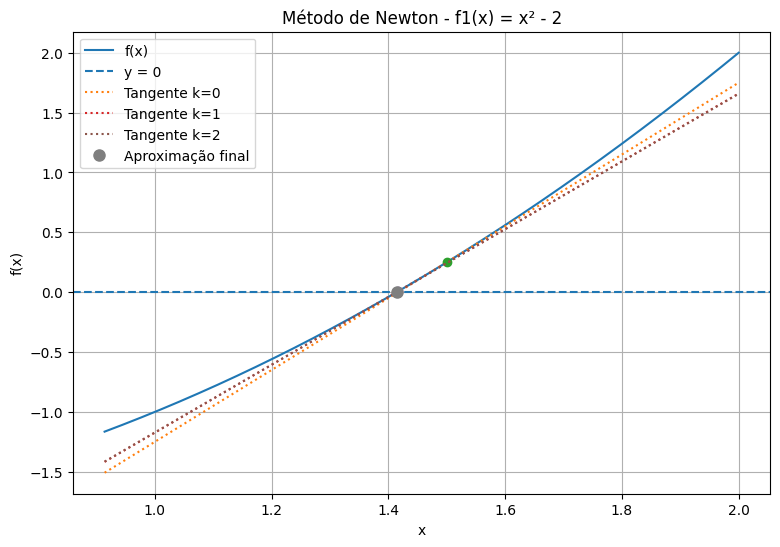

In [20]:
grafico_newton(
    f1,
    df1,
    n_f1,
    "Método de Newton - f1(x) = x² - 2"
)

In [21]:
def grafico_secantes(f, aproximacoes, titulo):

    x_min = min(aproximacoes) - 0.5
    x_max = max(aproximacoes) + 0.5

    x = np.linspace(x_min, x_max, 500)

    plt.figure(figsize=(9, 6))

    # Função
    plt.plot(x, f(x), label="f(x)")

    # Eixo x
    plt.axhline(0, linestyle="--", label="y = 0")

    # Mostrar as secantes
    for k in range(1, len(aproximacoes)):

        x_anterior = aproximacoes[k-1]
        x_atual = aproximacoes[k]

        y_anterior = f(x_anterior)
        y_atual = f(x_atual)

        # Evita divisão por zero
        if abs(x_atual - x_anterior) < 1e-14:
            continue

        inclinacao = (
            (y_atual - y_anterior)
            / (x_atual - x_anterior)
        )

        y_secante = (
            y_anterior
            + inclinacao * (x - x_anterior)
        )

        plt.plot(
            x,
            y_secante,
            linestyle=":",
            label=f"Secante k={k}"
        )

        plt.plot(
            [x_anterior, x_atual],
            [y_anterior, y_atual],
            "o"
        )

    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.title(titulo)
    plt.legend()
    plt.grid(True)
    plt.show()

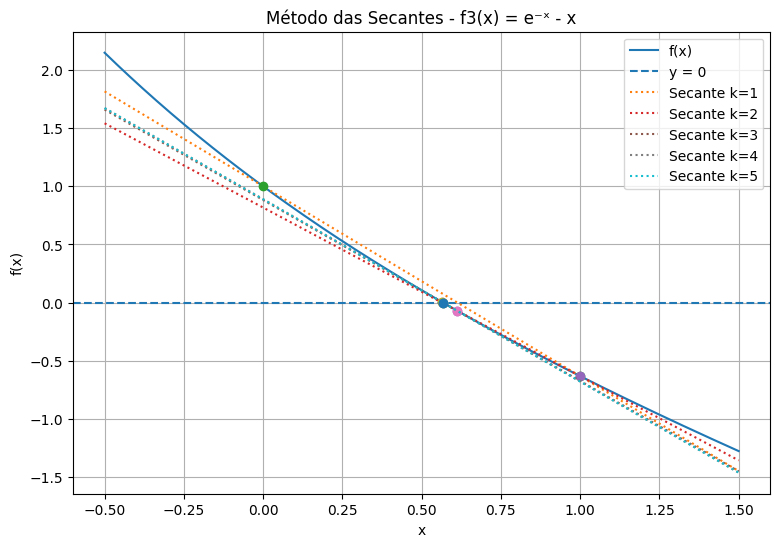

In [22]:
grafico_secantes(
    f3,
    s_f3,
    "Método das Secantes - f3(x) = e⁻ˣ - x"
)

In [ ]:
def historico_bissecao(f, a, b, tolerancia=1e-6, max_iter=100):

    historico = []

    for k in range(max_iter):

        x_medio = (a + b) / 2

        historico.append({
            "k": k,
            "a": a,
            "b": b,
            "x": x_medio,
            "f(x)": f(x_medio)
        })

        if abs(f(x_medio)) <= tolerancia:
            break

        if f(a) * f(x_medio) < 0:
            b = x_medio
        else:
            a = x_medio

    return historico